In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [15]:
import pandas as pd
import numpy as np
import tensorflow as tf


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [3]:
# 1. 데이터 불러오기
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/iris.csv")

In [4]:
df

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [6]:
# 2. one hot encoding 수행
y_df=pd.get_dummies(df['species'])

# species을 제외한 4 가지 특성만 추출
X_df=df.drop(columns=['species'])

# Keras 연산을 위해 pandas df를 numpy 배열로 변환
X=X_df.to_numpy()
y=y_df.to_numpy()

# 3. 학습/테스트 데이터 분리
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# 4. 데이터 정규화
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)


In [9]:
# 5. 모델 생성

model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(32, activation="relu" , input_shape=(4,)))
model.add(tf.keras.layers.Dense(16, activation="relu"))
model.add(tf.keras.layers.Dense(3, activation="softmax"))


# 6. 모델 설정
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])


In [10]:
# 7. 모델 구조 출력
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 739 (2.89 KB)

 Trainable params: 739 (2.89 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# 8. 모델 학습

history = model.fit(X_train_scaled, y_train,
                    epochs=30, #전체 데이터를 30번 반복 학습
                    batch_size=32, # 32개 묶음 단위로 가중치 업데이트
                    validation_split=0.2, # 학습 데이터 중 20%는 학습 경과 검증으로 사용
                    verbose=1)


Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8333 - loss: 0.8722 - val_accuracy: 0.7917 - val_loss: 0.9196
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8750 - loss: 0.8507 - val_accuracy: 0.8750 - val_loss: 0.8978
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8646 - loss: 0.8235 - val_accuracy: 0.9167 - val_loss: 0.8737
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8750 - loss: 0.7938 - val_accuracy: 0.9167 - val_loss: 0.8481
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8854 - loss: 0.7634 - val_accuracy: 0.9167 - val_loss: 0.8219
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8854 - loss: 0.7330 - val_accuracy: 0.9167 - val_loss: 0.7956
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9062 - loss: 0.7030 - val_accuracy: 0.9583 - val_loss: 0.7697
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.9062 - loss: 0.6747 - val_accuracy: 0.9583 - val_loss: 0.7444


In [22]:
# 9. 테스트 데이터 예측

y_prob = model.predict(X_test_scaled) #scaling된  test data 입력
y_pred = np.argmax(y_prob, axis=1)  # 예측된 확률 중 가장 높은 클래스 (0,1,2) 선택
y_true = np.argmax(y_test, axis=1)  # 원핫 인코딩 된 정답(y_test)를 정수 (0,1,2)로 변환


# 10. 성능 평가
acc=accuracy_score(y_true, y_pred)
print("\nAccuracy:", acc)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['setosa','versicolor','virginica']))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step

Accuracy: 0.7666666666666667

Confusion Matrix:
[[ 9  1  0]
 [ 0  4  6]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      0.90      0.95        10
  versicolor       0.80      0.40      0.53        10
   virginica       0.62      1.00      0.77        10

    accuracy                           0.77        30
   macro avg       0.81      0.77      0.75        30
weighted avg       0.81      0.77      0.75        30



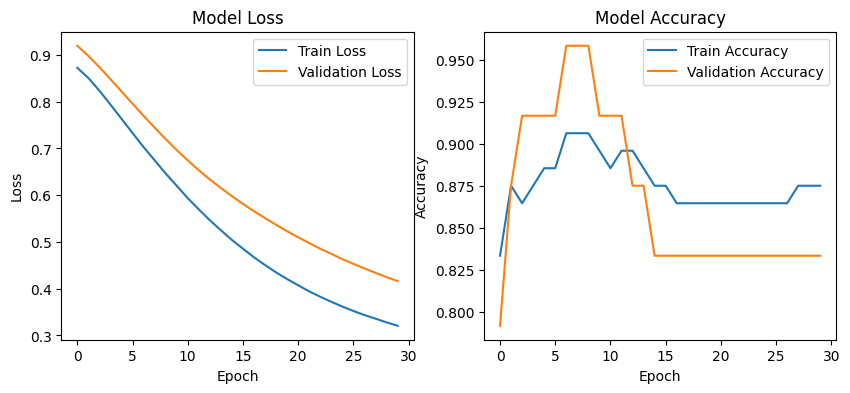

In [24]:
import matplotlib.pyplot as plt

# 손실(Loss) 시각화
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# 정확도(Accuracy) 시각화
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()